# E-Commerce Sales & Customer Analytics: EDA notebook

A walk-through of the project from raw data to findings. The data is **synthetic** (created with `src/01_generate_data.py`), all amounts are in INR, and "sales" means orders that are not Cancelled or Returned.

Steps in this notebook: load raw data, inspect problems, clean (short demo), explore, summarise findings.
The full pipeline lives in `src/`; this notebook does not repeat every analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
millions = FuncFormatter(lambda value, _: f"₹{value / 1e6:.0f}M")

## 1. Load and inspect the raw data

In [2]:
raw_orders = pd.read_csv("../data/raw/orders.csv")
print("Rows and columns:", raw_orders.shape)
raw_orders.head()

Rows and columns: (100300, 8)


,order_id,customer_id,order_date,order_status,payment_method,shipping_city,shipping_state,delivery_date
0,O000001,C01375,2025-01-01 00:03:11,Delivered,Credit Card,Kolkata,West Bengal,2025-01-03
1,O000002,C15817,2025-01-01 00:29:15,delivered,UPI,Thiruvananthapuram,Kerala,2025-01-04
2,O000003,C04036,2025-01-01 01:23:57,Delivered,Debit Card,Lucknow,Uttar Pradesh,2025-01-08
3,O000004,C09843,2025-01-01 02:07:07,Delivered,Cash on Delivery,Vadodara,Gujarat,2025-01-08
4,O000005,C10346,2025-01-01 02:37:46,Delivered,Cash on Delivery,Chennai,Tamil Nadu,2025-01-04


In [3]:
print("Missing values:")
print(raw_orders.isna().sum()[lambda s: s > 0])
print("\nDuplicate order_ids:", raw_orders["order_id"].duplicated().sum())
print("\nOrder status values:")
print(raw_orders["order_status"].value_counts())

Missing values:
shipping_state     502
delivery_date     5999
dtype: int64

Duplicate order_ids: 300

Order status values:
order_status
Delivered      85425
Returned        4203
Cancelled       3581
delivered       2625
DELIVERED       1339
Shipped         1257
Delivered        865
Processing       423
returned         128
cancelled        111
RETURNED          73
CANCELLED         50
Returned          44
shipped           43
Cancelled         31
delivered         31
DELIVERED         16
processing        15
SHIPPED           14
Shipped           11
PROCESSING         8
returned           2
Processing         2
CANCELLED          1
cancelled          1
shipped            1
Name: count, dtype: int64


In [4]:
raw_orders["payment_method"].value_counts()

payment_method
UPI                 36774
Credit Card         21394
Cash on Delivery    16711
Debit Card          15071
Net Banking          4847
Wallet               3042
upi                  1135
credit card           661
COD                   515
netbanking            150
Name: count, dtype: int64

The raw orders table has duplicate orders, inconsistent spelling (`delivered`, `DELIVERED`, `COD`, `upi`), missing delivery dates and some broken timestamps. These problems were added on purpose.

## 2. Clean the orders table (short demo)

The complete cleaning of all five tables is in `src/02_clean_data.py`. Here is the same logic for one table. (The full pipeline also removes orders left without any order line, so its row counts are slightly lower.)

In [5]:
payment_names = {"upi": "UPI", "credit card": "Credit Card", "debit card": "Debit Card",
                 "cash on delivery": "Cash on Delivery", "cod": "Cash on Delivery",
                 "net banking": "Net Banking", "netbanking": "Net Banking", "wallet": "Wallet"}

orders_demo = raw_orders.drop_duplicates(subset="order_id").copy()
orders_demo["order_status"] = orders_demo["order_status"].str.strip().str.title()
orders_demo["payment_method"] = orders_demo["payment_method"].str.strip().str.lower().map(payment_names)

orders_demo["order_date"] = pd.to_datetime(orders_demo["order_date"], errors="coerce")
orders_demo["delivery_date"] = pd.to_datetime(orders_demo["delivery_date"], errors="coerce")
print("Invalid order dates:", orders_demo["order_date"].isna().sum())
orders_demo = orders_demo.dropna(subset=["order_date"])

too_early = orders_demo["delivery_date"] < orders_demo["order_date"].dt.normalize()
print("Delivery before order:", too_early.sum())
orders_demo.loc[too_early, "delivery_date"] = pd.NaT

print("\nRows: raw", len(raw_orders), "-> cleaned", len(orders_demo))
orders_demo["order_status"].value_counts()

Invalid order dates: 100
Delivery before order: 282

Rows: raw 100300 -> cleaned 99900


order_status
Delivered     89939
Returned       4435
Cancelled      3760
Shipped        1319
Processing      447
Name: count, dtype: int64

## 3. Load the cleaned data and build one sales table

In [6]:
customers = pd.read_csv("../data/processed/customers.csv")
products = pd.read_csv("../data/processed/products.csv")
orders = pd.read_csv("../data/processed/orders.csv", parse_dates=["order_date", "delivery_date"])
order_items = pd.read_csv("../data/processed/order_items.csv")
reviews = pd.read_csv("../data/processed/reviews.csv")
customer_summary = pd.read_csv("../data/processed/customer_summary.csv")

# revenue = quantity x unit_price x (1 - discount), profit = revenue - cost  (already calculated in the cleaning step)
sales = (order_items.merge(orders, on="order_id")
                    .merge(products[["product_id", "product_name", "category", "subcategory"]], on="product_id"))
sales = sales[~sales["order_status"].isin(["Cancelled", "Returned"])]
sales["order_month"] = sales["order_date"].dt.to_period("M").dt.to_timestamp()
print(len(sales), "order lines from", sales["order_id"].nunique(), "valid orders")
sales[["order_id", "product_name", "category", "quantity", "unit_price", "discount", "revenue", "profit"]].head()

148933 order lines from 91641 valid orders


,order_id,product_name,category,quantity,unit_price,discount,revenue,profit
0,O000001,Urbane Green Tea Pack Neo,Grocery,4,109.00,0.00,436.00,67.88
1,O000002,Ardent Conditioner Essential,Beauty & Personal Care,1,639.00,0.15,543.15,235.30
2,O000002,Zenix Business Book Air,Books,1,429.00,0.00,429.00,169.33
3,O000002,Amara Green Tea Pack Air,Grocery,3,199.00,0.10,537.30,48.42
4,O000003,Mosaic Story Collection Lite,Books,1,259.00,0.05,246.05,74.88


## 4. Headline KPIs

In [7]:
total_revenue = sales["revenue"].sum()
total_profit = sales["profit"].sum()
valid_orders = sales["order_id"].nunique()

kpis = pd.Series({
    "Total revenue (INR)": total_revenue,
    "Total profit (INR)": total_profit,
    "Profit margin (%)": total_profit / total_revenue * 100,
    "Valid orders": valid_orders,
    "Customers with a sale": sales["customer_id"].nunique(),
    "Average order value (INR)": total_revenue / valid_orders,
})
kpis.to_frame("value")

,value
Total revenue (INR),"554,657,723.90"
Total profit (INR),"102,787,209.56"
Profit margin (%),18.53
Valid orders,"91,641.00"
Customers with a sale,"19,710.00"
Average order value (INR),"6,052.51"


## 5. Revenue over time

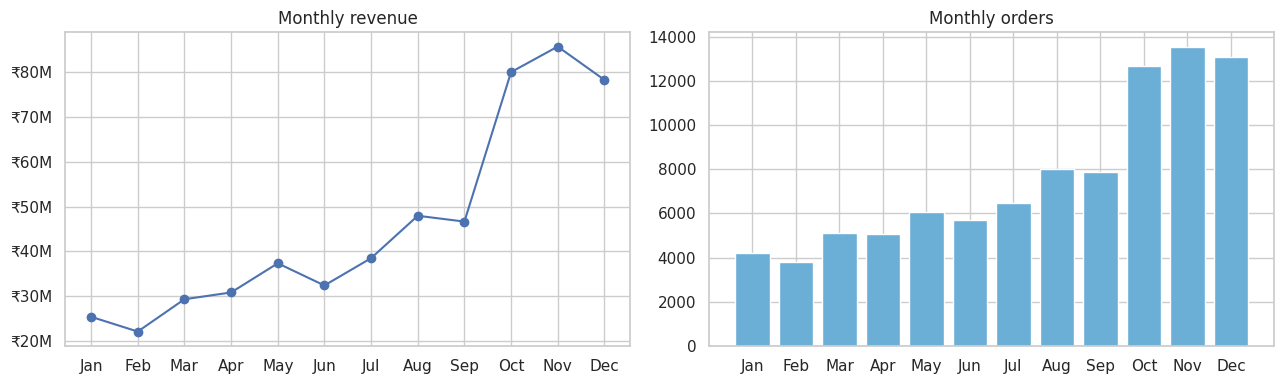

In [8]:
monthly = sales.groupby("order_month").agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(monthly.index.strftime("%b"), monthly["revenue"], marker="o")
axes[0].yaxis.set_major_formatter(millions)
axes[0].set_title("Monthly revenue")
axes[1].bar(monthly.index.strftime("%b"), monthly["orders"], color="#6baed6")
axes[1].set_title("Monthly orders")
plt.tight_layout()
plt.show()

In [9]:
festive_share = monthly.loc[monthly.index.month.isin([10, 11]), "revenue"].sum() / monthly["revenue"].sum() * 100
print(f"Oct-Nov (festive season) brings {festive_share:.1f}% of the year's revenue")

Oct-Nov (festive season) brings 29.9% of the year's revenue


## 6. Categories: revenue is not the same as profit

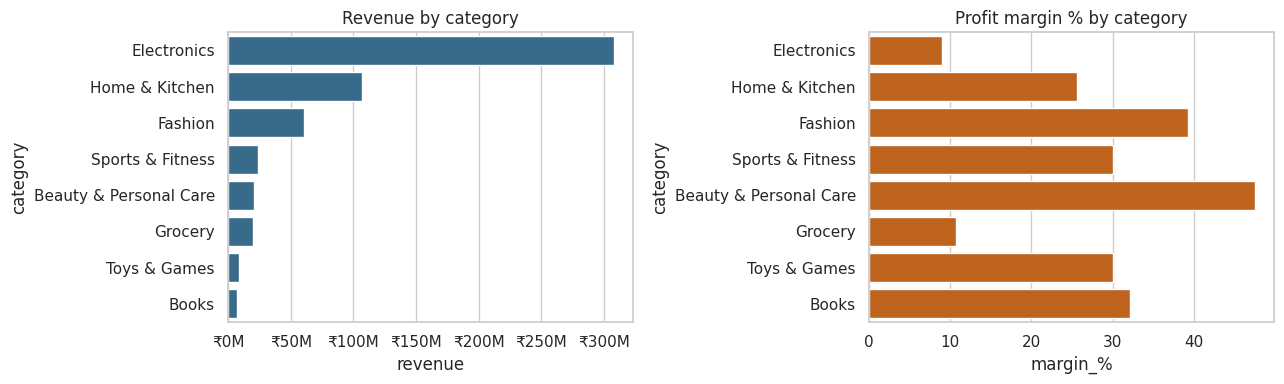

,revenue,profit,revenue_share_%,margin_%
category,,,,
Electronics,"307,644,527.60","27,653,058.00",55.50,9.00
Home & Kitchen,"106,950,847.00","27,437,439.00",19.30,25.70
Fashion,"60,510,030.70","23,798,691.20",10.90,39.30
Sports & Fitness,"23,856,897.30","7,167,866.00",4.30,30.00
Beauty & Personal Care,"20,646,993.20","9,811,707.20",3.70,47.50
Grocery,"19,484,783.10","2,098,079.40",3.50,10.80
Toys & Games,"8,667,706.80","2,601,925.60",1.60,30.00
Books,"6,895,938.30","2,218,443.20",1.20,32.20


In [10]:
by_category = sales.groupby("category").agg(revenue=("revenue", "sum"), profit=("profit", "sum"))
by_category["revenue_share_%"] = by_category["revenue"] / by_category["revenue"].sum() * 100
by_category["margin_%"] = by_category["profit"] / by_category["revenue"] * 100
by_category = by_category.sort_values("revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=by_category["revenue"], y=by_category.index, color="#2a6f97", ax=axes[0])
axes[0].xaxis.set_major_formatter(millions)
axes[0].set_title("Revenue by category")
sns.barplot(x=by_category["margin_%"], y=by_category.index, color="#d95f02", ax=axes[1])
axes[1].set_title("Profit margin % by category")
plt.tight_layout()
plt.show()
by_category.round(1)

## 7. Discounts: where do they hurt profit?

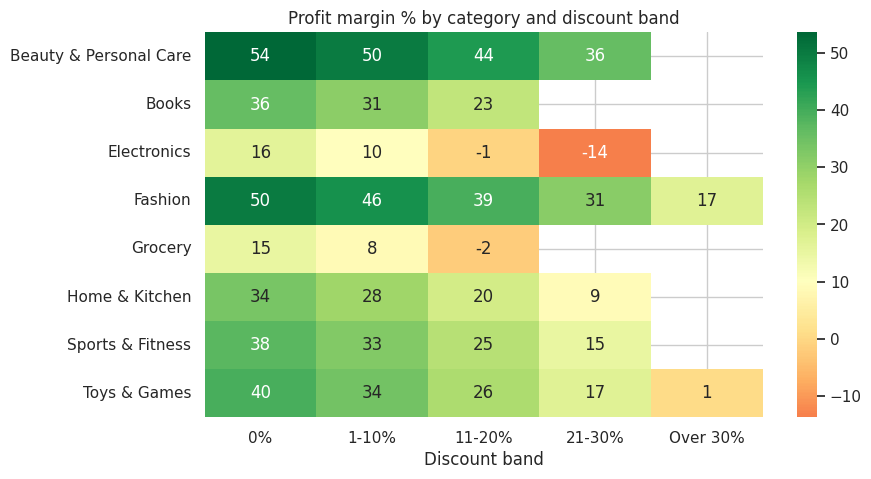

In [11]:
bands = pd.cut(sales["discount"], bins=[-0.01, 0, 0.10, 0.20, 0.30, 1.0],
               labels=["0%", "1-10%", "11-20%", "21-30%", "Over 30%"])
grouped = sales.groupby([sales["category"], bands], observed=True).agg(revenue=("revenue", "sum"), profit=("profit", "sum"))
margin_table = (grouped["profit"] / grouped["revenue"] * 100).unstack()

plt.figure(figsize=(9, 5))
sns.heatmap(margin_table, annot=True, fmt=".0f", cmap="RdYlGn", center=10)
plt.title("Profit margin % by category and discount band")
plt.ylabel("")
plt.xlabel("Discount band")
plt.show()

In [12]:
electronics = sales[sales["category"] == "Electronics"]
print(f"Electronics lines sold at a loss: {(electronics['profit'] < 0).mean() * 100:.1f}%")
print(f"Electronics lines with 11%+ discount that lost money: "
      f"{(electronics.loc[electronics['discount'] > 0.10, 'profit'] < 0).mean() * 100:.1f}%")

Electronics lines sold at a loss: 17.1%
Electronics lines with 11%+ discount that lost money: 61.4%


## 8. Geography

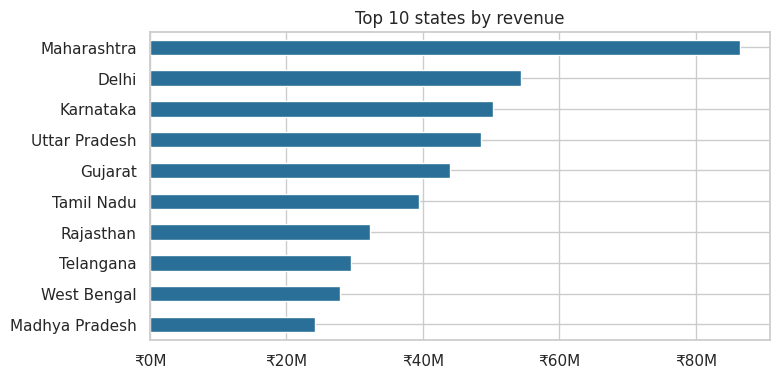

Top 5 states = 51.1% of revenue


In [13]:
by_state = sales.groupby("shipping_state")["revenue"].sum().sort_values(ascending=False)
top_states = by_state.head(10).sort_values()
ax = top_states.plot.barh(figsize=(8, 4), color="#2a6f97")
ax.xaxis.set_major_formatter(millions)
ax.set_title("Top 10 states by revenue")
ax.set_ylabel("")
plt.show()
print(f"Top 5 states = {by_state.head(5).sum() / by_state.sum() * 100:.1f}% of revenue")

## 9. Delivery performance

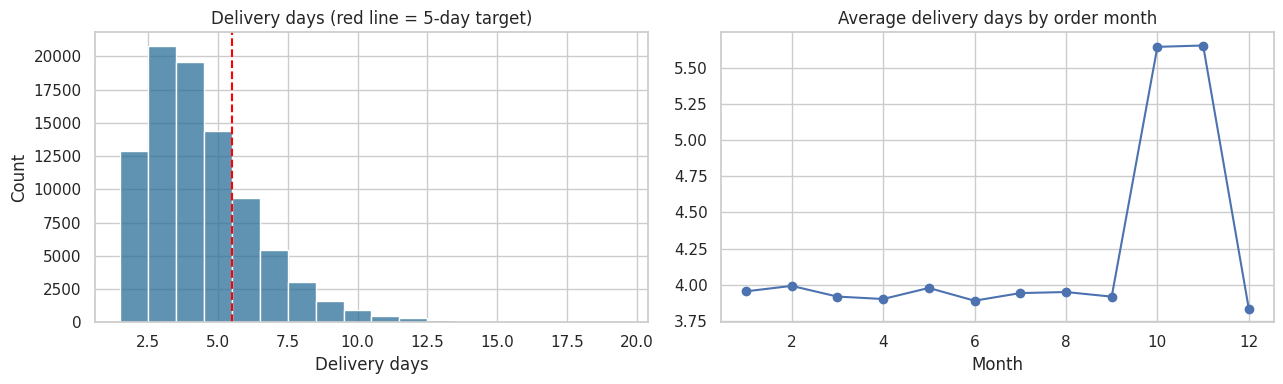

Average delivery: 4.42 days, 75.9% delivered within 5 days


In [14]:
delivered = orders[(orders["order_status"] == "Delivered") & orders["delivery_days"].notna()]
by_month = delivered.groupby(delivered["order_date"].dt.month)["delivery_days"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(delivered["delivery_days"], discrete=True, ax=axes[0], color="#2a6f97")
axes[0].set_xlabel("Delivery days")
axes[0].axvline(5.5, color="red", linestyle="--")
axes[0].set_title("Delivery days (red line = 5-day target)")
axes[1].plot(by_month.index, by_month.values, marker="o")
axes[1].set_title("Average delivery days by order month")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.show()
print(f"Average delivery: {delivered['delivery_days'].mean():.2f} days, "
      f"{(delivered['delivery_days'] <= 5).mean() * 100:.1f}% delivered within 5 days")

December looks fast only because orders placed late in December that are still in transit are not in the delivered group yet.

## 10. Customers

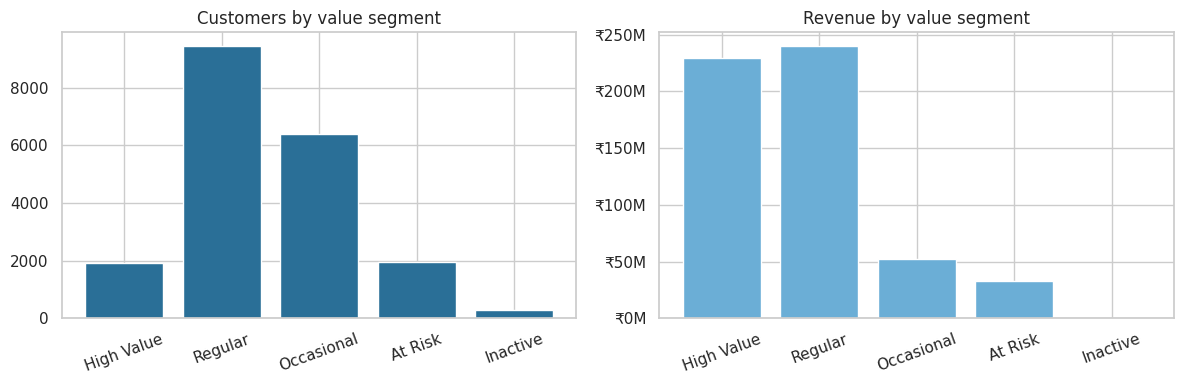

,customers,revenue,avg_orders,revenue_share_%
value_segment,,,,
High Value,1913,"229,587,546.00",13.00,41.40
Regular,9447,"240,069,322.20",5.50,43.30
Occasional,6391,"51,919,807.70",1.40,9.40
At Risk,1959,"33,081,048.00",2.80,6.00
Inactive,290,0.00,0.00,0.00


In [15]:
buyers = customer_summary[customer_summary["total_orders"] > 0]
segment_table = customer_summary.groupby("value_segment").agg(
    customers=("customer_id", "size"), revenue=("total_revenue", "sum"), avg_orders=("total_orders", "mean"))
segment_table["revenue_share_%"] = segment_table["revenue"] / segment_table["revenue"].sum() * 100
segment_table = segment_table.reindex(["High Value", "Regular", "Occasional", "At Risk", "Inactive"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(segment_table.index, segment_table["customers"], color="#2a6f97")
axes[0].set_title("Customers by value segment")
axes[1].bar(segment_table.index, segment_table["revenue"], color="#6baed6")
axes[1].yaxis.set_major_formatter(millions)
axes[1].set_title("Revenue by value segment")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
segment_table.round(1)

In [16]:
print(f"Repeat purchase rate: {(buyers['total_orders'] >= 2).mean() * 100:.1f}%")
top_20 = buyers["total_revenue"].sort_values(ascending=False).head(int(len(buyers) * 0.2)).sum()
print(f"Top 20% of customers bring {top_20 / buyers['total_revenue'].sum() * 100:.1f}% of revenue")

Repeat purchase rate: 81.8%
Top 20% of customers bring 62.6% of revenue


## 11. Ratings and returns

In [17]:
sub_ratings = (reviews.merge(products, on="product_id")
               .groupby(["category", "subcategory"])["rating"].agg(avg_rating="mean", reviews="size"))
sub_ratings[sub_ratings["reviews"] >= 200].sort_values("avg_rating").head(5)

,,avg_rating,reviews
category,subcategory,,
Toys & Games,Remote Control Toys,3.39,446
Fashion,Footwear,3.40,2362
Electronics,Smart Watches,3.41,1070
Toys & Games,Action Figures & Dolls,3.82,638
Electronics,Laptops,3.83,971


In [18]:
status_by_payment = pd.crosstab(orders["payment_method"], orders["order_status"], normalize="index") * 100
status_by_payment[["Cancelled", "Returned"]].round(1).sort_values("Cancelled", ascending=False)

order_status,Cancelled,Returned
payment_method,,
Cash on Delivery,8.00,4.10
Debit Card,3.10,4.40
Credit Card,3.00,4.50
UPI,2.80,4.50
Wallet,2.80,4.90
Net Banking,2.70,4.60


## 12. Findings (calculated from the data above)

In [19]:
top_category = by_category.index[0]
lowest_margin = by_category["margin_%"].idxmin()
best_margin = by_category["margin_%"].idxmax()
cod_cancel = status_by_payment.loc["Cash on Delivery", "Cancelled"]
other_cancel = status_by_payment.drop("Cash on Delivery")["Cancelled"].mean()
festive_delay = delivered[delivered["order_date"].dt.month.isin([10, 11])]["delivery_days"].mean()
normal_delay = delivered[delivered["order_date"].dt.month.between(1, 9)]["delivery_days"].mean()

print(f"1. {top_category} brings {by_category.loc[top_category, 'revenue_share_%']:.1f}% of revenue but only a {by_category.loc[top_category, 'margin_%']:.1f}% margin.")
print(f"2. {best_margin} has the best margin ({by_category.loc[best_margin, 'margin_%']:.1f}%), {lowest_margin} the lowest ({by_category.loc[lowest_margin, 'margin_%']:.1f}%).")
print(f"3. Discounts above 10% on Electronics push many lines below cost (see the heatmap).")
print(f"4. Cash on Delivery orders are cancelled {cod_cancel:.1f}% of the time vs {other_cancel:.1f}% for other payment methods.")
print(f"5. Delivery takes {festive_delay:.1f} days for Oct-Nov orders vs {normal_delay:.1f} days for Jan-Sep orders.")
print(f"6. The top 20% of customers bring {top_20 / buyers['total_revenue'].sum() * 100:.1f}% of revenue.")

1. Electronics brings 55.5% of revenue but only a 9.0% margin.
2. Beauty & Personal Care has the best margin (47.5%), Electronics the lowest (9.0%).
3. Discounts above 10% on Electronics push many lines below cost (see the heatmap).
4. Cash on Delivery orders are cancelled 8.0% of the time vs 2.9% for other payment methods.
5. Delivery takes 5.6 days for Oct-Nov orders vs 3.9 days for Jan-Sep orders.
6. The top 20% of customers bring 62.6% of revenue.
